**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**18 | Out-of-Fold CNN Confidence and Error Audit**

![Stage 18 scientific workflow](../../images/18_workflow.svg)

**Objective:** Examine the uncalibrated softmax confidence and errors of the weighted CNN on participant-held-out Development predictions, including minority activities.

**Dataset:** The 29-participant HARTH v2.0 Development cohort, with 14,201 base-500 evaluation windows and no access to reserved Test IDs S023 and S032.

**Notebook Scope:** Fit the 1,000-cap weighted CNN under the 400-update protocol from Notebook 17, collect out-of-fold probabilities and examine reliability, class errors and confident mistakes. Softmax scores are not validated clinical uncertainty estimates.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Reusable Confidence-Audit Utilities**

In [2]:
# ============ 01. Imports and Reusable Confidence-Audit Utilities ============

# ---------------------- Study Environment Configuration ----------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------------------- Standard Library ------------------------------
import sys
from pathlib import Path

# ------------------ Scientific Computing and Visualisation -------------------
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

# ----------------------- PyTorch and Notebook Display ------------------------
import torch

from IPython.display import display

# ---------------------- Grouped Evaluation and Metrics -----------------------
from sklearn.model_selection import GroupKFold

from sklearn.metrics import f1_score

# ------------------------- Repository Configuration --------------------------
root = Path.cwd().resolve()

while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Open this notebook inside the repository.")
    root = root.parent

# ----------------------- Shared and Study Module Paths -----------------------
sys.path.insert(0, str(root / "python_modules"))

sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- HARTH and Fixed-Step Inference Utilities ------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_nested_window_cohort

from core.temporal_cnn import (
    train_temporal_cnn_fixed_steps, predict_temporal_cnn_probabilities,
)

# ------------------- Confidence and Reliability Utilities --------------------
from core.prediction_reliability import audit_prediction_confidence

# --------------------------- Scientific Plot Style ---------------------------
from core.plot_style import plot_style
plot_style()

# ------------------------- Compute Device Selection --------------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type


Compute device and system information
OS: Linux 6.6.122+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda


**02. Prepare the Development Cohort**

Reuse the nested windowing protocol from Notebook 17. Validation uses only base-500 windows; expanded training windows are limited to fold Train participants. Reserved Test recordings are excluded before loading.

In [3]:
# ==================== 02. Prepare the Development Cohort =====================

# ------------------- Development Cohort and Reserved Test --------------------
RESERVED_TEST = {"S023", "S032"}

SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------------------ Documented Eight-Class Task ------------------------
TASK_CLASSES = tuple(range(1, 9))

# --------------------- Nested Development Source Windows ---------------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,  # Keep original base windows for held-out evaluation.
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------------- Original Base Window and Subject IDs --------------------
base_rows = np.flatnonzero(metadata["in_base_500"].to_numpy(dtype=bool))

y = metadata["label"].to_numpy()

group_ids = metadata["subject_id"].to_numpy()

# -------------------- Cohort Integrity and Source Counts ---------------------
assert len(SUBJECTS) == 29 and len(base_rows) == 14201

assert not (set(group_ids) & RESERVED_TEST)

print("Expanded input:", X.shape, "| Original Validation candidates:", len(base_rows))


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Expanded input: (28201, 6, 100) | Original Validation candidates: 14201


**03. Generate Out-of-Fold Softmax Predictions**

Fit one weighted CNN per participant-disjoint fold for 400 optimiser updates, with Train-derived class weights. Record final-step eight-class softmax predictions and original source-row identifiers. Each base-500 window is held out once.

In [4]:
# =============== 03. Generate Out-of-Fold Softmax Predictions ================

# --------------------- Fixed-Step and Fold Configuration ---------------------
FOLDS, STEPS = 3, 400

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------- Participant-Disjoint GroupKFold ----------------------
folds = GroupKFold(n_splits=FOLDS)

# --------------------- Out-of-Fold Prediction Containers ---------------------
records, fold_metrics = [], []

# ----------------- Train-Only CNN Fitting and Probabilities ------------------
for fold, (tr, va) in enumerate(
    folds.split(np.zeros(len(base_rows)), y[base_rows], groups=group_ids[base_rows]),
    start=1,
):
    base_train = base_rows[tr]
    validation = base_rows[va]
    train_subjects = set(group_ids[base_train])
    validation_subjects = set(group_ids[validation])
    assert not (train_subjects & validation_subjects)
    train_rows = np.flatnonzero(np.isin(group_ids, list(train_subjects)))

    # Fit 1,000-cap Weighted CNN on Train people only.
    model, history, predicted, train_stats = train_temporal_cnn_fixed_steps(
        X_train=X[train_rows], y_train=y[train_rows],
        X_validation=X[validation], y_validation=y[validation],
        classes=TASK_CLASSES, max_steps=STEPS, eval_every=100,
        batch_size=128, learning_rate=1e-3, seed=42,
        device=device, class_weighting="inverse_sqrt",
    )
    probabilities = predict_temporal_cnn_probabilities(
        model, X[validation], train_stats, TASK_CLASSES,
        batch_size=256, device=device,
    )
    assert np.array_equal(
        np.asarray(TASK_CLASSES)[probabilities.argmax(axis=1)], predicted
    ), "Probability inference must match the final-step prediction."
    records.append(pd.DataFrame({
        "fold": fold, "source_row": validation,
        "subject_id": group_ids[validation],
        "true_label": y[validation],
        **{f"prob_{code}": probabilities[:, i]
           for i, code in enumerate(TASK_CLASSES)},
    }))
    fold_metrics.append({
        "fold": fold, "validation_subjects": len(validation_subjects),
        "validation_windows": len(validation),
        "macro_f1": f1_score(
            y[validation], predicted, labels=TASK_CLASSES,
            average="macro", zero_division=0,
        ),
    })
    print("Completed fold", fold)

# ---------------------- Held-Out Source-Row Provenance -----------------------
oof = pd.concat(records, ignore_index=True).sort_values("source_row")

# ----------------------- Fold-Level Evaluation Summary -----------------------
display(pd.DataFrame(fold_metrics).round(4))


Step 100/400 | loss=0.8877 | Validation Macro F1=0.5862
Step 200/400 | loss=0.4701 | Validation Macro F1=0.7494
Step 300/400 | loss=0.3450 | Validation Macro F1=0.7400
Step 400/400 | loss=0.2571 | Validation Macro F1=0.7585
Completed fold 1
Step 100/400 | loss=0.8686 | Validation Macro F1=0.5879
Step 200/400 | loss=0.4489 | Validation Macro F1=0.6824
Step 300/400 | loss=0.3275 | Validation Macro F1=0.7783
Step 400/400 | loss=0.2569 | Validation Macro F1=0.7996
Completed fold 2
Step 100/400 | loss=0.8687 | Validation Macro F1=0.5765
Step 200/400 | loss=0.4949 | Validation Macro F1=0.6087
Step 300/400 | loss=0.3644 | Validation Macro F1=0.7372
Step 400/400 | loss=0.3287 | Validation Macro F1=0.8208
Completed fold 3


,fold,validation_subjects,validation_windows,macro_f1
0,1,10,5000,0.7585
1,2,10,4701,0.7996
2,3,9,4500,0.8208


**04. Verify Prediction Provenance and Confidence Metrics**

Check the one-to-one alignment of predictions and held-out source windows. Recorded window-level accuracy was 0.9458, mean maximum softmax 0.9005, ten-bin ECE 0.0453 and multiclass Brier score 0.0905. Forty incorrect predictions had maximum softmax of at least 0.90. These values describe uncalibrated Development predictions.

In [5]:
# ========== 04. Verify Prediction Provenance and Confidence Metrics ==========

# -------------------------- Held-Out Row Integrity ---------------------------
assert len(oof) == len(base_rows)

assert oof["source_row"].is_unique

# ------------------ Source Index and Class Label Alignment -------------------
np.testing.assert_array_equal(oof["source_row"].to_numpy(), np.sort(base_rows))

np.testing.assert_array_equal(
    oof["true_label"].to_numpy(), y[np.sort(base_rows)]
)

# ---------------------- Documented Softmax Class Order -----------------------
prob_columns = [f"prob_{code}" for code in TASK_CLASSES]

# -------------------- Reliability and Confidence Metrics ---------------------
details, reliability, by_subject, summary = audit_prediction_confidence(
    y_true=oof["true_label"].to_numpy(),
    probabilities=oof[prob_columns].to_numpy(),
    subjects=oof["subject_id"].to_numpy(),
    classes=TASK_CLASSES, n_bins=10,
)

# ------------------------ Fold and Source Provenance -------------------------
details["fold"] = oof["fold"].to_numpy()

details["source_row"] = oof["source_row"].to_numpy()

# --------------------- Accuracy, ECE and Brier Summaries ---------------------
display(pd.DataFrame([summary]).round(4))

display(reliability.round(4))

print("Note: uncalibrated softmax, not validated uncertainty.")


,windows,accuracy,mean_confidence,ece_10_bins,multiclass_brier,high_confidence_errors_0_90
0,14201,0.9458,0.9002,0.0456,0.0907,39


,bin,lower,upper,windows,mean_confidence,observed_accuracy
0,0,0.0,0.1,0,NaN,NaN
1,1,0.1,0.2,0,NaN,NaN
2,2,0.2,0.3,53,0.2755,0.3962
3,3,0.3,0.4,286,0.3583,0.4580
4,4,0.4,0.5,353,0.4530,0.5637
5,5,0.5,0.6,404,0.5510,0.7079
6,6,0.6,0.7,455,0.6513,0.7780
7,7,0.7,0.8,777,0.7571,0.8687
8,8,0.8,0.9,1568,0.8567,0.9560
9,9,0.9,1.0,10305,0.9758,0.9962


Note: uncalibrated softmax, not validated uncertainty.


**05. Inspect Reliability and Softmax Confidence**

Compare mean confidence and empirical correctness within fixed-width bins. Because windows overlap within recordings, reliability statistics are descriptive; ECE also depends on the binning scheme.

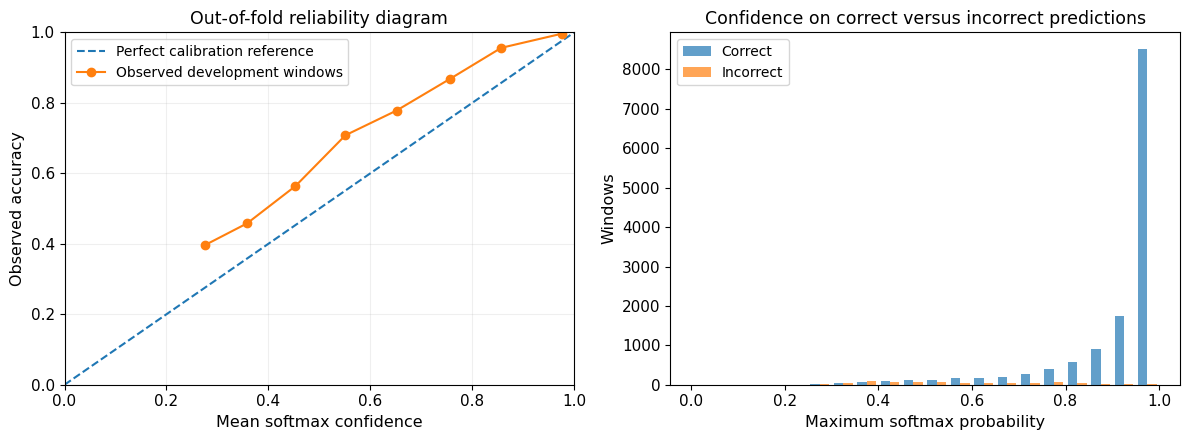

In [6]:
# ============== 05. Inspect Reliability and Softmax Confidence ===============

# ---------------------------- Reliability Diagram ----------------------------
used = reliability.loc[reliability["windows"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration reference")

axes[0].plot(
    used["mean_confidence"], used["observed_accuracy"],
    marker="o", label="Observed development windows",
)

axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean softmax confidence",
            ylabel="Observed accuracy", title="Out-of-fold reliability diagram")
axes[0].legend()
axes[0].grid(alpha=0.2)

# -------------- Correct and Incorrect Confidence Distributions ---------------
correct = details.loc[details["correct"], "confidence"]

wrong = details.loc[~details["correct"], "confidence"]

axes[1].hist([correct, wrong], bins=np.linspace(0, 1, 21),
             label=["Correct", "Incorrect"], alpha=0.7)
axes[1].set(xlabel="Maximum softmax probability", ylabel="Windows",
            title="Confidence on correct versus incorrect predictions")
axes[1].legend()
fig.tight_layout()
plt.show()


**06. Examine Minority-Class Errors and Confident Mistakes**

Inspect class support, recall and high-confidence incorrect predictions. Shuffling recall was 0.1233 across 219 held-out windows despite overall accuracy of 0.9458. Aggregate accuracy therefore does not capture minority-class performance.

In [7]:
# ========= 06. Examine Minority-Class Errors and Confident Mistakes ==========

# ------------------ Class-Wise Confidence and Error Records ------------------
class_table = []

for code in TASK_CLASSES:
    part = details.loc[details["true_label"] == code]
    mistakes = part.loc[~part["correct"]]
    class_table.append({
        "class": ACTIVITY_NAMES[code], "support": len(part),
        "recall": float(part["correct"].mean()) if len(part) else np.nan,
        "errors": len(mistakes),
        "high_confidence_errors_0_90":
            int((mistakes["confidence"] >= 0.90).sum()),
        "mean_error_confidence":
            float(mistakes["confidence"].mean()) if len(mistakes) else np.nan,
    })

class_report = pd.DataFrame(class_table)

# ----------------------- Activity-Level Error Summary ------------------------
display(class_report.round(4))

# --------------------- Confident Mistakes by Participant ---------------------
display(by_subject.sort_values("high_confidence_errors", ascending=False).round(4))

confident_errors = details.loc[
    (~details["correct"]) & (details["confidence"] >= 0.9)
]

# -------------------- Frequent True-Predicted Class Pairs --------------------
confusion_pairs = (confident_errors
    .groupby(["true_label", "predicted_label"])
    .size().rename("windows").reset_index()
    .sort_values("windows", ascending=False))

display(confusion_pairs.head(15))


,class,support,recall,errors,high_confidence_errors_0_90,mean_error_confidence
0,Walking,3591,0.9290,255,3,0.4846
1,Running,1028,0.9951,5,0,0.5518
2,Shuffling,219,0.1233,192,8,0.5640
3,Stairs ascending,192,0.7344,51,0,0.5128
4,Stairs descending,182,0.6593,62,8,0.6782
5,Standing,2227,0.9546,101,20,0.5715
6,Sitting,5599,0.9816,103,0,0.7295
7,Lying,1163,0.9991,1,0,0.5337


,subject_id,windows,accuracy,errors,mean_error_confidence,high_confidence_errors
26,S036,500,0.9340,33,0.5810,9
9,S017,500,0.9320,34,0.6784,7
5,S013,500,0.9120,44,0.5536,5
10,S018,500,0.9340,33,0.6793,5
0,S006,500,0.9740,13,0.5136,3
6,S014,500,0.9380,31,0.5082,2
2,S009,201,0.8955,21,0.6004,2
16,S025,500,0.9640,18,0.6449,2
7,S015,500,0.9720,14,0.6639,1
13,S021,500,0.9220,39,0.5731,1


,true_label,predicted_label,windows
5,6,7,20
4,5,1,8
2,3,6,4
0,1,6,3
1,3,1,2
3,3,7,2


**07. Scientific Quality Gate and Limitations**

Verify source-row coverage, probability structure and participant separation. No temperature scaling, abstention policy, threshold optimisation or independent Test evaluation is performed; uncalibrated softmax should not be interpreted as clinically reliable uncertainty.

In [8]:
# ================ 07. Scientific Quality Gate and Limitations ================

# ------------------- Development and Out-of-Fold Coverage --------------------
assert len(details) == 14201

assert oof["source_row"].is_unique

assert details["subject_id"].nunique() == 29

assert not (set(details["subject_id"]) & RESERVED_TEST)

# --------------- Confidence Probability and Calibration Checks ---------------
assert int(reliability["windows"].sum()) == len(details)

assert np.allclose(oof[prob_columns].sum(axis=1), 1, atol=1e-5)

assert 0 <= summary["accuracy"] <= 1

assert 0 <= summary["ece_10_bins"] <= 1

# ------------------- Quality Gate and Evidence Limitations -------------------
print("Out-of-fold softmax confidence audit: PASSED")

print("Original reserved Test used: NO")

print("Calibration or clinical uncertainty validity established: NO")


Out-of-fold softmax confidence audit: PASSED
Original reserved Test used: NO
Calibration or clinical uncertainty validity established: NO
